# E-Commerce User Behavior Analytics & Conversion Optimization

This notebook is the guided analysis surface for the modular pipeline. The source modules remain the reproducible implementation; the notebook is for inspecting product definitions, outputs, and model behavior.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from ecommerce_analytics.config import ProjectConfig
from ecommerce_analytics.pipeline import run_pipeline
config = ProjectConfig(project_root=PROJECT_ROOT)

## Run the reproducible pipeline

Uncomment the next line after placing the raw files in `data/raw/`. Use `force=True` only when data or feature definitions change.

In [2]:
# run_pipeline(config, force=True)

## Product metrics and funnel

The purchase metric is an observed event, not a verified order. Funnel stages require chronological progression inside the same session.

,metric,value
0,view_sessions,69453.000000
1,cart_after_view_sessions,4194.000000
2,purchase_after_view_sessions,3700.000000
3,purchase_after_cart_sessions,2040.000000
4,view_to_cart_rate,0.060386
5,view_to_purchase_rate,0.053273
6,cart_to_purchase_rate,0.486409


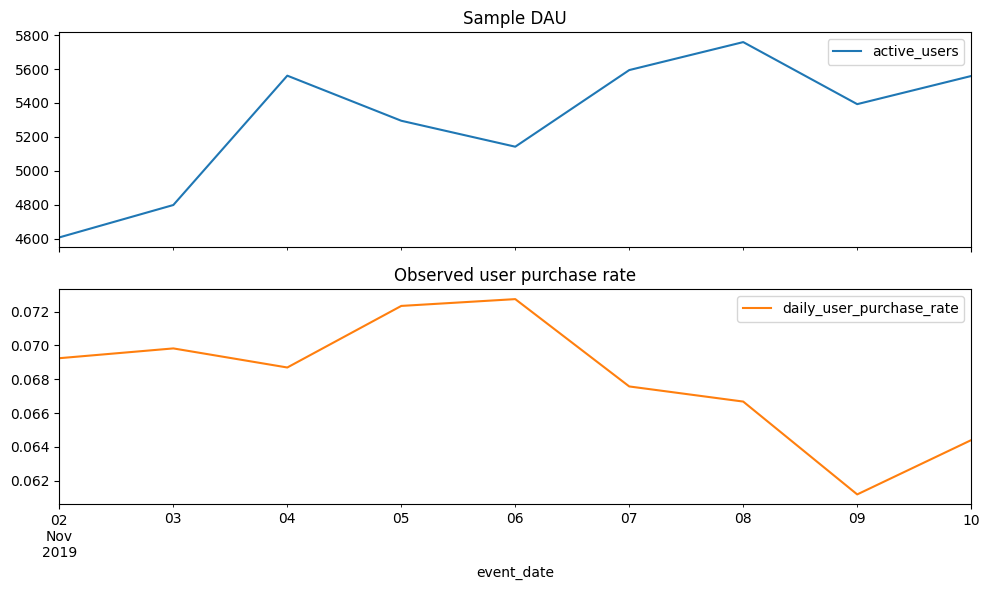

In [3]:
daily = pd.read_csv(config.tables_dir / 'daily_metrics.csv', parse_dates=['event_date'])
funnel = pd.read_csv(config.tables_dir / 'funnel_summary.csv')
display(funnel)
daily[['event_date', 'active_users', 'daily_user_purchase_rate']].plot(
    x='event_date', subplots=True, figsize=(10, 6), title=['Sample DAU', 'Observed user purchase rate']
)
plt.tight_layout();

## Segment and cohort diagnostics

Cohort date means first activity observed in the downloaded window, not true acquisition. Segment comparisons are descriptive and generate experiment hypotheses.

In [4]:
segments = pd.read_csv(config.tables_dir / 'segment_funnels.csv')
retention = pd.read_csv(config.tables_dir / 'cohort_retention.csv')
display(segments.query("dimension == 'entry_category' and sessions >= 100")
        .sort_values('view_to_purchase_rate', ascending=False).head(10))
display(retention)

,segment,sessions,view_sessions,cart_after_view_sessions,purchase_after_view_sessions,purchase_after_cart_sessions,dimension,view_to_cart_rate,view_to_purchase_rate,cart_to_purchase_rate
7,electronics,28913,28903,2461,2032,1365,entry_category,0.085147,0.070304,0.554653
2,appliances,6265,6264,323,344,154,entry_category,0.051564,0.054917,0.476780
13,unknown,21985,21984,1028,996,382,entry_category,0.046761,0.045306,0.371595
9,kids,789,789,32,34,14,entry_category,0.040558,0.043093,0.437500
4,computers,3853,3852,121,122,52,entry_category,0.031412,0.031672,0.429752
3,auto,1089,1089,53,34,18,entry_category,0.048669,0.031221,0.339623
5,construction,830,830,33,24,10,entry_category,0.039759,0.028916,0.303030
0,accessories,278,278,8,8,2,entry_category,0.028777,0.028777,0.250000
1,apparel,3103,3103,74,71,28,entry_category,0.023848,0.022881,0.378378
11,sport,210,210,3,4,0,entry_category,0.014286,0.019048,0.000000


,cohort_date,horizon_days,eligible_users,retained_users,retention_rate
0,2019-11-02,1,4607,839,0.182114
1,2019-11-02,7,4607,602,0.130671
2,2019-11-03,1,3959,658,0.166204
3,2019-11-03,7,3959,422,0.106593
4,2019-11-04,1,4178,577,0.138104
5,2019-11-05,1,3499,459,0.131180
6,2019-11-06,1,3083,421,0.136555
7,2019-11-07,1,3252,381,0.117159
8,2019-11-08,1,3199,327,0.102219
9,2019-11-09,1,2762,307,0.111151


## Leakage-safe conversion modeling

Features use only the first five minutes of each eligible session. The target is a later purchase in the same session, and the final validation period occurs after all training sessions.

In [5]:
metrics = pd.read_csv(config.tables_dir / 'model_metrics.csv')
shap_importance = pd.read_csv(config.tables_dir / 'shap_importance.csv')
display(metrics)
display(shap_importance.head(15))

,model,roc_auc,average_precision,precision,recall,f1,brier_score,threshold
0,logistic_regression,0.819021,0.135830,0.180000,0.265823,0.214651,0.016546,0.082023
1,lightgbm,0.813457,0.127956,0.184397,0.219409,0.200385,0.016456,0.159571
2,historical_rate,0.500000,0.017677,0.000000,0.000000,0.000000,0.017368,0.020629


,feature,mean_abs_shap
0,numeric__observed_events,0.464628
1,numeric__min_price,0.243960
2,numeric__prior_sessions,0.217791
3,numeric__max_price,0.198172
4,numeric__session_hour,0.173376
5,numeric__cart_count,0.151899
6,numeric__mean_price,0.128799
7,numeric__day_of_week,0.128635
8,numeric__price_range,0.117042
9,categorical__entry_brand_other,0.113654


## Decision layer

Use `reports/product_report.md` for grounded findings and `reports/experiment_plan.md` for the proposed randomized cart-recovery test. Do not interpret SHAP values or observational conversion gaps as treatment effects.